# Part 1, extension 2b: does the network work in countries it has never seen?

The network was trained on Brazil, Indonesia, DR Congo and India. Here it's tested, **unchanged**, on Peru and Myanmar, using patches built by notebook 05 with exactly the same rules. Nothing is retrained or tuned on these countries.

- **Peru** is Amazon rainforest, like Brazil. This is a test across a border, in a forest type the network knows.
- **Myanmar** has seasonal tropical forest, mining and small clearings, more like India, where the network was weakest. This is the harder test.

Before any number is reported, the notebook checks that:
1. the saved model still reproduces notebook 02's test results exactly (the same check as notebook 04),
2. the new patches and their labels agree with the index file from notebook 05, and that no new patch comes from a training country, and
3. the new images are scaled with the **training** statistics, just as a real new country would be.

Scores come with 95% bootstrap ranges, because 500 patches per country leaves some uncertainty.

## 1. Setup

In [1]:
import os
import json
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet18
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             precision_recall_fscore_support, ConfusionMatrixDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Must match notebook 02 exactly
PATCH_DIR = "../data/raw/part1_patches"
INDEX_CSV = "../data/cleaned/part1_patch_index.csv"
OUT_DIR = "../outputs"
MODEL_PATH = "../models/part1_resnet18.pt"
PRED_CSV = "../outputs/part1_test_predictions.csv"
SEED = 42
SPLIT = (0.70, 0.15, 0.15)
BANDS = ["B2", "B3", "B4", "B8", "B11", "B12"]
CHANNELS = [f"{b}_{t}" for t in ("before", "after") for b in BANDS]

# The never-seen countries, from notebook 05
UNSEEN_DIR = "../data/raw/part1_unseen"
UNSEEN_CSV = "../data/cleaned/part1_unseen_index.csv"
N_BOOT = 2000

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(SEED)
device = torch.device("mps" if torch.backends.mps.is_available()
                      else "cuda" if torch.cuda.is_available() else "cpu")
print("Running on", device)

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Running on mps


## 2. Rebuild the training scaling and the trained model

The next three cells are copied unchanged from notebook 02, and the check after them from notebook 04.

In [2]:
index = pd.read_csv(INDEX_CSV)

Xs, ys, ids = [], [], []
for fname in sorted(os.listdir(PATCH_DIR)):
    if fname.endswith(".npz"):
        z = np.load(os.path.join(PATCH_DIR, fname), allow_pickle=True)
        Xs.append(z["X"]); ys.append(z["y"]); ids.extend(z["patch_id"].tolist())
X = np.concatenate(Xs)                      # (patches, 12, 64, 64), whole numbers (uint16)
meta = index.set_index("patch_id").loc[ids].reset_index()
y = meta["label"].to_numpy(np.int64)        # 0 = stable forest, 1 = forest lost

assert len(X) == len(meta) == len(index), "the .npz files and the index CSV disagree; rerun step 1 sections 7"
assert (np.concatenate(ys) == y).all(), "labels in the .npz files and the index CSV disagree"
assert meta["patch_id"].is_unique
print(f"{len(X)} patches, {X.shape[1]} bands of {X.shape[2]}x{X.shape[3]} pixels")
print(meta.groupby(["country", "label"]).size().unstack().rename(columns={0: "stable", 1: "lost"}))

6292 patches, 12 bands of 64x64 pixels
label                             stable  lost
country                                       
Brazil                              1000  1000
Democratic Republic of the Congo    1000   516
India                                455   473
Indonesia                            946   902


In [3]:
def split_blocks(meta, fractions, seed):
    rng = np.random.default_rng(seed)
    part = pd.Series("", index=meta.index)
    for country, g in meta.groupby("country"):
        blocks = g["block"].unique()
        rng.shuffle(blocks)
        share = g.groupby("block").size().loc[blocks].cumsum() / len(g)   # running share of patches
        names = np.where(share <= fractions[0], "train",
                         np.where(share <= fractions[0] + fractions[1], "val", "test"))
        part.loc[g.index] = g["block"].map(dict(zip(blocks, names)))
    return part

n_countries = meta["country"].nunique()
for attempt in range(200):
    meta["split"] = split_blocks(meta, SPLIT, SEED + attempt)
    classes = meta.groupby(["country", "split"])["label"].nunique()
    if len(classes) == n_countries * 3 and (classes == 2).all():
        break
else:
    raise RuntimeError("could not find a block split with both classes everywhere; lower the test share")

assert meta.groupby("block")["split"].nunique().max() == 1, "a block ended up in two groups"
tr = np.where(meta["split"] == "train")[0]
va = np.where(meta["split"] == "val")[0]
te = np.where(meta["split"] == "test")[0]
print(f"Split found on attempt {attempt + 1}: {len(tr)} train, {len(va)} validation, {len(te)} test")
print(meta.groupby(["country", "split", "label"]).size().unstack().rename(columns={0: "stable", 1: "lost"}))

Split found on attempt 1: 4312 train, 930 validation, 1050 test
label                                   stable  lost
country                          split              
Brazil                           test      151   154
                                 train     690   701
                                 val       159   145
Democratic Republic of the Congo test      183    62
                                 train     648   383
                                 val       169    71
India                            test       98    84
                                 train     290   327
                                 val        67    62
Indonesia                        test      158   160
                                 train     668   605
                                 val       120   137


/var/folders/b9/6zcj3lks1sj71xf32vysyr8h0000gn/T/ipykernel_11313/2938831922.py:6: UserWarning: you are shuffling a 'ArrowStringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  rng.shuffle(blocks)
/var/folders/b9/6zcj3lks1sj71xf32vysyr8h0000gn/T/ipykernel_11313/2938831922.py:6: UserWarning: you are shuffling a 'ArrowStringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  rng.shuffle(blocks)
/var/folders/b9/6zcj3lks1sj71xf32vysyr8h0000gn/T/ipykernel_11313/2938831922.py:6: UserWarning: you are shuffling a 'ArrowStringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplic

In [4]:
mean = np.array([X[tr, c].astype(np.float32).mean() for c in range(X.shape[1])], dtype=np.float32)
std = np.array([X[tr, c].astype(np.float32).std() for c in range(X.shape[1])], dtype=np.float32)
MEAN = torch.tensor(mean).view(1, -1, 1, 1).to(device)
STD = torch.tensor(std).view(1, -1, 1, 1).to(device)

def to_batch(idx, augment=False):
    xb = torch.from_numpy(X[idx].astype(np.float32)).to(device)
    xb = (xb - MEAN) / STD
    if augment:
        xb = torch.stack([torch.rot90(x, random.randint(0, 3), dims=(1, 2)) for x in xb])
        flip = torch.rand(len(xb), device=device) < 0.5
        xb[flip] = torch.flip(xb[flip], dims=(3,))
    return xb, torch.from_numpy(y[idx]).to(device)

print(pd.DataFrame({"mean": mean, "std": std}, index=CHANNELS).round(0))

              mean    std
B2_before    972.0  104.0
B3_before    836.0  102.0
B4_before    548.0  114.0
B8_before   2613.0  416.0
B11_before  1408.0  247.0
B12_before   559.0  143.0
B2_after    1011.0  111.0
B3_after     882.0  121.0
B4_after     602.0  159.0
B8_after    2649.0  439.0
B11_after   1535.0  377.0
B12_after    637.0  246.0


In [5]:
def build_model():
    model = resnet18(weights=None)                   # weights come from our saved file below
    old = model.conv1.weight.data                    # (64, 3, 7, 7), filters for red, green, blue
    rgb_for = {0: 2, 1: 1, 2: 0}                     # our B2 = blue, B3 = green, B4 = red
    new = torch.empty(64, len(CHANNELS), 7, 7)
    for c in range(len(CHANNELS)):
        b = c % len(BANDS)
        new[:, c] = old[:, rgb_for[b]] if b in rgb_for else old.mean(dim=1)
    model.conv1 = nn.Conv2d(len(CHANNELS), 64, kernel_size=7, stride=2, padding=3, bias=False)
    model.conv1.weight.data = new * 3 / len(CHANNELS)   # keep the layer's output at the same scale
    model.maxpool = nn.Identity()                    # 64x64 patches are small: skip one shrinking step
    model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.fc.in_features, 2))
    return model

model = build_model().to(device)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))   # strict: every layer must match
model.eval()

@torch.no_grad()
def predict(net, idx):
    net.eval()
    probs = []
    for s in range(0, len(idx), 256):
        xb, _ = to_batch(idx[s:s + 256])
        probs.append(F.softmax(net(xb), dim=1)[:, 1].cpu())
    return torch.cat(probs).numpy()

saved = pd.read_csv(PRED_CSV)
assert set(saved["patch_id"]) == set(meta["patch_id"].iloc[te]), \
    "the test patches differ from notebook 02's; the split did not come out the same"
saved = saved.set_index("patch_id").loc[meta["patch_id"].iloc[te]]
p_now = predict(model, te)
gap = np.abs(p_now - saved["prob_lost"].to_numpy())
agree = ((p_now > 0.5).astype(int) == saved["predicted"].to_numpy()).mean()
print(f"Largest difference from the saved probabilities: {gap.max():.4f}")
print(f"Same lost/stable call as notebook 02 on {agree:.1%} of {len(te)} test patches")
print(f"Balanced accuracy now {balanced_accuracy_score(y[te], p_now > 0.5):.3f}")
assert gap.max() < 0.01 and agree >= 0.999, "the model does not reproduce notebook 02's results; stop here"
print("Check 1 passed")

Largest difference from the saved probabilities: 0.0000
Same lost/stable call as notebook 02 on 100.0% of 1050 test patches
Balanced accuracy now 0.938
Check 1 passed


## 3. Load the never-seen countries and check them

In [6]:
uidx = pd.read_csv(UNSEEN_CSV)
UX, Uy, Uids = [], [], []
for fname in sorted(os.listdir(UNSEEN_DIR)):
    if fname.endswith(".npz"):
        z = np.load(os.path.join(UNSEEN_DIR, fname), allow_pickle=True)
        UX.append(z["X"]); Uy.append(z["y"]); Uids.extend(z["patch_id"].tolist())
UX = np.concatenate(UX)
umeta = uidx.set_index("patch_id").loc[Uids].reset_index()
uy = umeta["label"].to_numpy(np.int64)

assert UX.shape[1:] == X.shape[1:], f"patch shape {UX.shape[1:]} differs from training {X.shape[1:]}"
assert len(UX) == len(umeta) == len(uidx), "the unseen .npz files and their index CSV disagree"
assert (np.concatenate(Uy) == uy).all(), "labels in the unseen .npz files and the index CSV disagree"
overlap = set(umeta["country"]) & set(meta["country"])
assert not overlap, f"these countries were in training: {overlap}"
assert umeta["patch_id"].str.startswith("u").all(), "unseen patch ids should start with 'u'"
print(f"{len(UX)} never-seen patches, none from a training country")
print(umeta.groupby(["country", "label"]).size().unstack().rename(columns={0: "stable", 1: "lost"}))

# How different do the new images look? Band averages compared with the training average
shift = pd.DataFrame({c: [UX[umeta.country.to_numpy() == c][:, k].astype(np.float32).mean() for k in range(len(CHANNELS))]
                      for c in sorted(umeta.country.unique())}, index=CHANNELS)
shift["training_mean"] = mean
print("\nBand averages, new countries vs training (scaled with the training numbers, as a real new country would be):")
print(shift.round(0).to_string())

961 never-seen patches, none from a training country
label    stable  lost
country              
Myanmar     250   211
Peru        250   250

Band averages, new countries vs training (scaled with the training numbers, as a real new country would be):
            Myanmar    Peru  training_mean
B2_before     942.0   866.0          972.0
B3_before     806.0   747.0          836.0
B4_before     517.0   446.0          548.0
B8_before    2490.0  2691.0         2613.0
B11_before   1377.0  1399.0         1408.0
B12_before    570.0   521.0          559.0
B2_after      952.0   928.0         1011.0
B3_after      827.0   804.0          882.0
B4_after      542.0   505.0          602.0
B8_after     2504.0  2703.0         2649.0
B11_after    1434.0  1467.0         1535.0
B12_after     613.0   561.0          637.0


## 4. Test the network, unchanged

In [7]:
@torch.no_grad()
def predict_array(arr):
    model.eval()
    probs = []
    for s in range(0, len(arr), 256):
        xb = torch.from_numpy(arr[s:s + 256].astype(np.float32)).to(device)
        xb = (xb - MEAN) / STD
        probs.append(F.softmax(model(xb), dim=1)[:, 1].cpu())
    return torch.cat(probs).numpy()

# Same scaling path as to_batch(): confirm on a few training-test patches before trusting it
assert np.allclose(predict_array(X[te[:50]]), p_now[:50], atol=1e-4), "predict_array does not match to_batch"

up = predict_array(UX)
upred = (up > 0.5).astype(int)

def boot_ci(yt, yp, fn, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n):
        i = rng.integers(0, len(yt), len(yt))
        if len(np.unique(yt[i])) == 2:
            vals.append(fn(yt[i], yp[i]))
    return np.percentile(vals, [2.5, 97.5])

rows = {}
countries = umeta["country"].to_numpy()
for c in sorted(set(countries)) + ["Both"]:
    m = np.ones(len(uy), bool) if c == "Both" else countries == c
    prec, rec, _, _ = precision_recall_fscore_support(uy[m], upred[m], labels=[0, 1], zero_division=0)
    lo, hi = boot_ci(uy[m], upred[m], balanced_accuracy_score)
    rows[c] = {"patches": int(m.sum()), "accuracy": accuracy_score(uy[m], upred[m]),
               "balanced_accuracy": balanced_accuracy_score(uy[m], upred[m]),
               "bal_acc_95%_low": lo, "bal_acc_95%_high": hi,
               "precision_lost": prec[1], "recall_lost": rec[1],
               "confusion_matrix": confusion_matrix(uy[m], upred[m], labels=[0, 1]).tolist()}
res = pd.DataFrame(rows).T
print(res.drop(columns="confusion_matrix").astype(float).round(3).to_string())

# For comparison: the same network on its own test areas (notebook 02), by country
own = json.load(open(os.path.join(OUT_DIR, "part1_metrics.json")))["per_country"]
print("\nOn its own test areas (notebook 02), balanced accuracy:",
      ", ".join(f"{k} {v['balanced_accuracy']:.3f}" for k, v in own.items()))

         patches  accuracy  balanced_accuracy  bal_acc_95%_low  bal_acc_95%_high  precision_lost  recall_lost
Myanmar    461.0     0.937              0.936            0.913             0.957           0.933        0.929
Peru       500.0     0.936              0.936            0.914             0.955           0.904        0.976
Both       961.0     0.937              0.937            0.922             0.952           0.917        0.954

On its own test areas (notebook 02), balanced accuracy: Brazil 0.954, Democratic Republic of the Congo 0.962, India 0.840, Indonesia 0.956


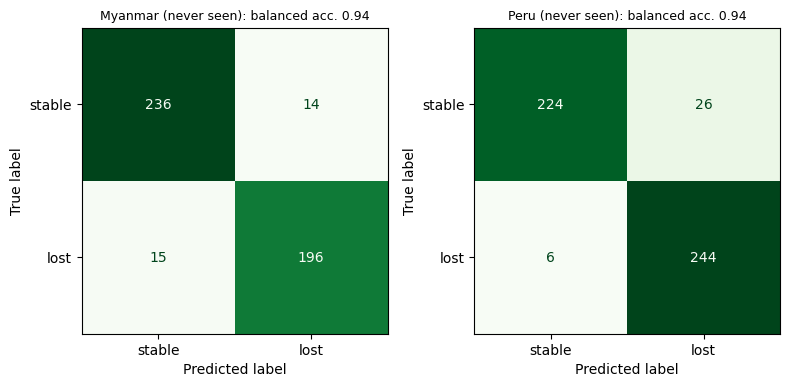

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, c in zip(axes, [c for c in rows if c != "Both"]):
    ConfusionMatrixDisplay(np.array(rows[c]["confusion_matrix"]), display_labels=["stable", "lost"]).plot(
        ax=ax, cmap="Greens", colorbar=False)
    ax.set_title(f"{c} (never seen): balanced acc. {rows[c]['balanced_accuracy']:.2f}", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "part1_unseen_confusion.png"), dpi=150)
plt.show()

## 5. The simple comparison model in the new countries

The NDVI logistic regression from notebook 02 is refit on the same training patches and tested on Peru and Myanmar. If the neural network's lead holds up in new countries, that's evidence it learned something more general than "greenness dropped".

In [9]:
def ndvi(red, nir):
    return (nir - red) / (nir + red + 1e-6)

def simple_features(idx, chunk=500):
    rows = []
    for s in range(0, len(idx), chunk):          # in chunks, to keep memory use low
        Xi = X[idx[s:s + chunk]].astype(np.float32)
        before, after = ndvi(Xi[:, 2], Xi[:, 3]), ndvi(Xi[:, 8], Xi[:, 9])   # red and near infrared
        change = after - before
        rows.append(np.column_stack([
            before.mean((1, 2)), after.mean((1, 2)), change.mean((1, 2)),
            np.percentile(change, 10, axis=(1, 2)), change.min((1, 2)),
            Xi.mean(axis=(2, 3)),
        ]))
    return np.concatenate(rows)

baseline = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))
baseline.fit(simple_features(tr), y[tr])

def simple_features_new(arr, chunk=500):
    rows_ = []
    for s in range(0, len(arr), chunk):
        Xi = arr[s:s + chunk].astype(np.float32)
        before, after = ndvi(Xi[:, 2], Xi[:, 3]), ndvi(Xi[:, 8], Xi[:, 9])
        change = after - before
        rows_.append(np.column_stack([before.mean((1, 2)), after.mean((1, 2)), change.mean((1, 2)),
                                      np.percentile(change, 10, axis=(1, 2)), change.min((1, 2)),
                                      Xi.mean(axis=(2, 3))]))
    return np.concatenate(rows_)

# The new-array version must give identical features to notebook 02's version
assert np.allclose(simple_features_new(X[te[:100]]), simple_features(te[:100])), "feature code differs from notebook 02"
ubase = baseline.predict(simple_features_new(UX))
comp = {}
for c in sorted(set(countries)) + ["Both"]:
    m = np.ones(len(uy), bool) if c == "Both" else countries == c
    comp[c] = {"ResNet-18": balanced_accuracy_score(uy[m], upred[m]),
               "Simple model": balanced_accuracy_score(uy[m], ubase[m])}
print("Balanced accuracy in never-seen countries:")
print(pd.DataFrame(comp).T.round(3).to_string())

Balanced accuracy in never-seen countries:
         ResNet-18  Simple model
Myanmar      0.936         0.913
Peru         0.936         0.816
Both         0.937         0.862


In [10]:
out = umeta[["patch_id", "country", "lat", "lon", "label"]].copy()
out["prob_lost"] = up.round(4)
out["predicted"] = upred
out.to_csv(os.path.join(OUT_DIR, "part1_unseen_predictions.csv"), index=False)
result = {
    "countries_never_seen": sorted(set(countries)),
    "model": "notebook 02 ResNet-18, unchanged; scaled with training statistics",
    "check1_reproduces_notebook02": {"max_prob_gap": float(gap.max()), "same_call_share": float(agree)},
    "by_country": {c: {k: (v if k == "confusion_matrix" else float(v)) for k, v in r.items()} for c, r in rows.items()},
    "baseline_balanced_accuracy": {c: float(v["Simple model"]) for c, v in comp.items()},
    "own_test_areas_balanced_accuracy": {k: v["balanced_accuracy"] for k, v in own.items()},
}
with open(os.path.join(OUT_DIR, "part1_unseen_metrics.json"), "w") as f:
    json.dump(result, f, indent=2)
print("Saved part1_unseen_metrics.json and part1_unseen_predictions.csv")

Saved part1_unseen_metrics.json and part1_unseen_predictions.csv


## 6. What this does and doesn't show

- **Hotspots only.** Patches come from each country's main deforestation regions and are clear-cut cases (as in training), so this is the network's best-case performance in a new country.
- **Two countries.** Two countries are evidence, not proof, that the network travels. Other forest types (dry forest, mangroves) are untested.
- **Labels come from Hansen.** Accuracy means agreement with Hansen's map.
- **The ranges matter.** If two scores' 95% ranges overlap, treat them as similar.

## Sources

- Patches built by notebook 05 (Sentinel-2 via Earth Engine; Hansen v1.11 labels, CC BY 4.0). Hotspot sources are listed there.